# FaST-LMM on GPU and in float32: is it worthwhile?

FaST-LMM has always computed in float64. Consumer NVIDIA GPUs (for example, the RTX 3060) run float64
at 1/64 of their float32 rate, so earlier GPU experiments, which were float64, ran at roughly CPU speed.

This notebook runs `single_snp` on the same data in a 2×2 grid:

| | float64 | float32 |
|---|---|---|
| **CPU** (`xp="numpy"`) | reference | only the number format changes |
| **GPU** (`xp="cupy"`) | only the device changes | the fast mode |

and reports, for each cell, time and agreement with the CPU float64 reference.

**Run it in an environment with CuPy**, for example the experiment venv:
`~/.cache/fastlmm-gpu/venv` (FaST-LMM and PySnpTools installed editable, plus `cupy-cuda13x[ctk]`).
GPU support needs the PySnpTools fix that lets `SnpData` hold CuPy arrays (branch `cupy-sub-matrix`).
Without CuPy, the notebook runs only the CPU column and says so.

Sizes start small. Enlarge `SIZES` only when the small results justify it.

In [1]:
import os
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pysnptools.snpreader import SnpData, SnpGen

from fastlmm.association import single_snp

try:
    import cupy as cp

    GPU_NAME = cp.cuda.runtime.getDeviceProperties(0)["name"].decode()
except ModuleNotFoundError:
    cp = None
    GPU_NAME = None

print(f"python {platform.python_version()}, numpy {np.__version__}, cpu_count {os.cpu_count()}")
print(f"cupy {cp.__version__ if cp else 'not installed'}, GPU {GPU_NAME}")
if cp is None:
    print("*** CuPy is not available: only the CPU (numpy) column will run. ***")

MODES = [("numpy", "float64"), ("numpy", "float32")]
if cp is not None:
    MODES += [("cupy", "float64"), ("cupy", "float32")]
REFERENCE = ("numpy", "float64")

python 3.13.13, numpy 2.5.4, cpu_count 32
cupy 14.2.0, GPU NVIDIA GeForce RTX 3060


## Synthetic data

Genotypes come from PySnpTools' `SnpGen`. The phenotype has 20 causal test SNPs, a polygenic background
from the kernel SNPs, and noise. `hard=True` adds the cases most likely to expose float32 problems:
10% duplicated individuals (a singular kernel), 10% rare test SNPs (MAF 0.5–1%), and very little noise.

In [2]:
def make_data(iid_count, test_sid_count, k0_sid_count, hard=False, seed=1):
    rng = np.random.default_rng(seed)
    snps = SnpGen(seed=seed, iid_count=iid_count, sid_count=test_sid_count + k0_sid_count, chrom_count=5, block_size=1000).read()
    val = snps.val.copy()
    if hard:
        dup_count = iid_count // 10
        source = rng.choice(iid_count - dup_count, dup_count, replace=False)
        val[iid_count - dup_count :] = val[source]
        rare_count = test_sid_count // 10
        rare = rng.binomial(2, rng.uniform(0.005, 0.01, rare_count), (iid_count, rare_count)).astype(np.float64)
        rare[0, rare.std(0) == 0] = 1.0  # no all-zero columns
        val[:, :rare_count] = rare
    # Contiguous copies: PySnpTools subsetting requires F- or C-contiguous val.
    test_snps = SnpData(iid=snps.iid, sid=snps.sid[:test_sid_count], val=np.asfortranarray(val[:, :test_sid_count]), pos=snps.pos[:test_sid_count])
    k0 = SnpData(iid=snps.iid, sid=snps.sid[test_sid_count:], val=np.asfortranarray(val[:, test_sid_count:]), pos=snps.pos[test_sid_count:])

    def standardized(a):
        a = np.nan_to_num(a - np.nanmean(a, 0))
        return a / np.where(a.std(0) == 0, 1, a.std(0))

    causal = rng.choice(test_sid_count, 20, replace=False)
    g = standardized(k0.val) / np.sqrt(k0_sid_count)
    # Genetic background variance is about 1 at every size (g's columns are scaled by 1/sqrt(k0_sid_count)).
    pheno_val = standardized(test_snps.val[:, causal]) @ rng.normal(0, 0.15, 20) + g @ rng.normal(0, 1.0, k0_sid_count)
    pheno_val += rng.normal(0, 0.1 if hard else 1.0, iid_count)
    pheno = SnpData(iid=snps.iid, sid=["pheno"], val=pheno_val[:, None])
    covar = SnpData(iid=snps.iid, sid=["c1", "c2"], val=rng.standard_normal((iid_count, 2)))
    return test_snps, k0, pheno, covar

## Running the grid

Each mode runs once untimed (CuPy compiles kernels and creates solver handles on first use), then once timed.
GPU timings include host-to-device copies, standardization, and building the result table, so they are
end-to-end `single_snp` times, not just kernel times.

In [3]:
def run_mode(data, xp, dtype, force_low_rank, h2=None):
    test_snps, k0, pheno, covar = data
    return single_snp(
        test_snps=test_snps, K0=k0, pheno=pheno, covar=covar, h2=h2,
        leave_out_one_chrom=False, force_low_rank=force_low_rank, force_full_rank=not force_low_rank,
        count_A1=False, xp=xp, dtype=dtype,
    ).set_index("SNP").sort_index()


def run_grid(data, force_low_rank, h2=None, label=""):
    frames, rows = {}, []
    for xp, dtype in MODES:
        run_mode(data, xp, dtype, force_low_rank, h2)  # warm-up
        start = time.perf_counter()
        frames[(xp, dtype)] = run_mode(data, xp, dtype, force_low_rank, h2)
        rows.append({"label": label, "rank": "low" if force_low_rank else "full", "xp": xp, "dtype": dtype, "time (s)": time.perf_counter() - start})
    ref = frames[REFERENCE]
    ref_top = set(ref.PValue.nsmallest(20).index)
    for row, (mode, frame) in zip(rows, frames.items()):
        dlog = np.abs(np.log10(frame.PValue) - np.log10(ref.PValue))
        row["max |Δlog10 p|"] = dlog.max()
        row["median |Δlog10 p|"] = dlog.median()
        row["top-20 overlap"] = len(ref_top & set(frame.PValue.nsmallest(20).index))
        for threshold in [1e-5, 5e-8]:
            row[f"hits<{threshold:g} ref/run"] = f"{(ref.PValue < threshold).sum()}/{(frame.PValue < threshold).sum()}"
        row["Nullh2"] = frame.Nullh2.iloc[0]
        row["speedup vs ref"] = rows[0]["time (s)"] / row["time (s)"]
    return pd.DataFrame(rows), frames

## 1. Size sweep

`SIZES` are (individuals, test SNPs, kernel SNPs). Full rank uses all kernel SNPs as an N×N kernel;
low rank uses the kernel SNPs directly (needs kernel SNPs < individuals).

In [4]:
SIZES = [(1_000, 5_000, 500), (2_000, 10_000, 1_000), (4_000, 20_000, 2_000)]
# Scale up only when the small results justify it:
# SIZES += [(10_000, 50_000, 5_000), (20_000, 50_000, 10_000)]

sweep_tables = []
for iid_count, test_sid_count, k0_sid_count in SIZES:
    data = make_data(iid_count, test_sid_count, k0_sid_count)
    for force_low_rank in [False, True]:
        table, _ = run_grid(data, force_low_rank, label=f"N={iid_count}")
        table.insert(1, "iid_count", iid_count)
        sweep_tables.append(table)
sweep = pd.concat(sweep_tables, ignore_index=True)
pd.set_option("display.width", 200)
sweep

/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserW

/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserW

... (56 outputs left out)

/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


,label,iid_count,rank,xp,dtype,time (s),max |Δlog10 p|,median |Δlog10 p|,top-20 overlap,hits<1e-05 ref/run,hits<5e-08 ref/run,Nullh2,speedup vs ref
0,N=1000,1000,full,numpy,float64,0.492358,0.000000e+00,0.000000e+00,20,12/12,10/10,0.270734,1.000000
1,N=1000,1000,full,numpy,float32,0.855670,3.061570e-06,1.621714e-07,20,12/12,10/10,0.270734,0.575407
2,N=1000,1000,full,cupy,float64,0.258744,1.165033e-07,2.309030e-09,20,12/12,10/10,0.270734,1.902875
3,N=1000,1000,full,cupy,float32,0.173881,6.147689e-06,4.606253e-07,20,12/12,10/10,0.270734,2.831586
4,N=1000,1000,low,numpy,float64,0.335815,0.000000e+00,0.000000e+00,20,12/12,10/10,0.270734,1.000000
5,N=1000,1000,low,numpy,float32,0.276585,1.015824e-05,1.208832e-07,20,12/12,10/10,0.270734,1.214149
6,N=1000,1000,low,cupy,float64,0.395214,4.618528e-14,1.637579e-15,20,12/12,10/10,0.270734,0.849705
7,N=1000,1000,low,cupy,float32,0.250161,1.149423e-05,6.733788e-07,20,12/12,10/10,0.270734,1.342398
8,N=2000,2000,full,numpy,float64,1.847031,0.000000e+00,0.000000e+00,20,42/42,26/26,0.473526,1.000000
9,N=2000,2000,full,numpy,float32,1.292519,4.548053e-06,1.794351e-07,20,42/42,26/26,0.473526,1.429017


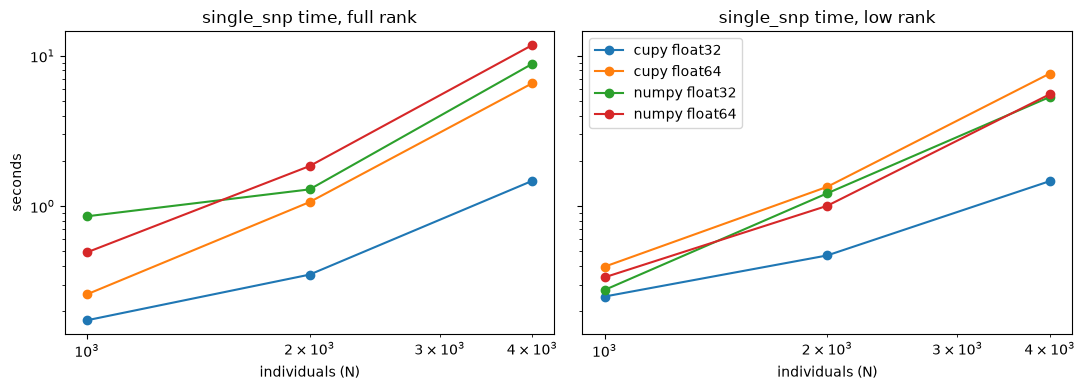

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, rank in zip(axes, ["full", "low"]):
    for (xp, dtype), group in sweep[sweep["rank"] == rank].groupby(["xp", "dtype"]):
        ax.plot(group.iid_count, group["time (s)"], marker="o", label=f"{xp} {dtype}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("individuals (N)")
    ax.set_title(f"single_snp time, {rank} rank")
axes[0].set_ylabel("seconds")
axes[1].legend()
plt.tight_layout()

## 2. Hard case: duplicates, rare variants, and h2 pinned at 0.99

With h2 = 0.99 the noise floor `1 - h2` is 0.01, so the smallest kernel eigenvalues dominate the
rotated covariance. This is where float32 rounding is most likely to matter. `h2` is passed to
`single_snp` directly, so every mode uses exactly the same h2.

In [6]:
hard_data = make_data(2_000, 10_000, 1_000, hard=True)
hard_tables, hard_frames = [], {}
for h2 in [None, 0.99]:
    for force_low_rank in [False, True]:
        table, frames = run_grid(hard_data, force_low_rank, h2=h2, label=f"hard h2={h2 or 'fit'}")
        hard_tables.append(table)
        hard_frames[(h2, force_low_rank)] = frames
pd.concat(hard_tables, ignore_index=True)

/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


... (25 outputs left out)

/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(
/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserW

/home/carlk/programs/PySnpTools/pysnptools/util/__init__.py:364: UserWarning: Converting float64 to float32 can cause loss of information
  warnings.warn(


,label,rank,xp,dtype,time (s),max |Δlog10 p|,median |Δlog10 p|,top-20 overlap,hits<1e-05 ref/run,hits<5e-08 ref/run,Nullh2,speedup vs ref
0,hard h2=fit,full,numpy,float64,1.800577,0.000000e+00,0.000000e+00,20,89/89,51/51,0.742858,1.000000
1,hard h2=fit,full,numpy,float32,1.231858,1.666571e-05,1.791653e-07,20,89/89,51/51,0.742858,1.461676
2,hard h2=fit,full,cupy,float64,1.067766,2.287948e-12,4.912737e-15,20,89/89,51/51,0.742858,1.686303
3,hard h2=fit,full,cupy,float32,0.363321,7.999236e-05,1.152043e-06,20,89/89,51/51,0.742859,4.955885
4,hard h2=fit,low,numpy,float64,1.701919,0.000000e+00,0.000000e+00,20,89/89,51/51,0.742858,1.000000
5,hard h2=fit,low,numpy,float32,1.178296,4.060107e-05,1.286590e-07,20,89/89,51/51,0.742858,1.444390
6,hard h2=fit,low,cupy,float64,1.332638,1.919276e-06,3.738649e-09,20,89/89,51/51,0.742858,1.277106
7,hard h2=fit,low,cupy,float32,0.486066,4.176305e-05,8.297645e-07,20,89/89,51/51,0.742858,3.501415
8,hard h2=0.99,full,numpy,float64,1.235672,0.000000e+00,0.000000e+00,20,158/158,94/94,0.990000,1.000000
9,hard h2=0.99,full,numpy,float32,1.106968,4.291732e-04,1.752491e-06,20,158/158,94/94,0.990000,1.116267


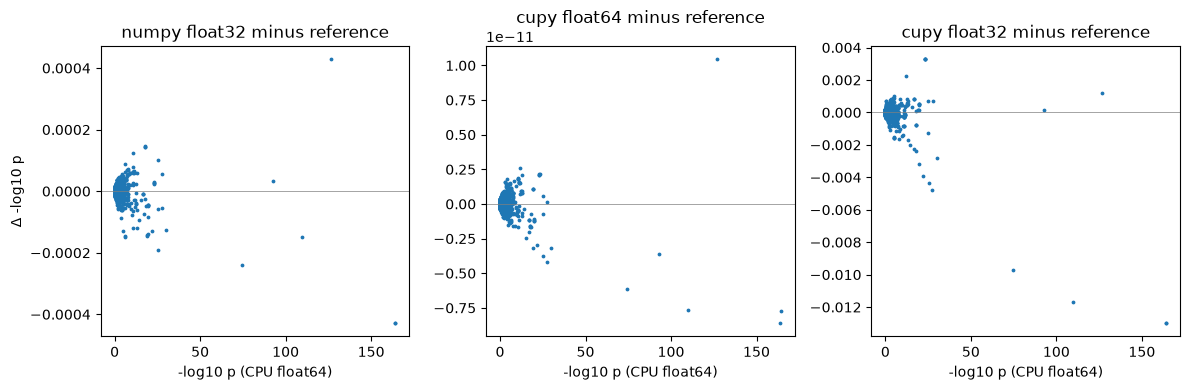

In [7]:
frames = hard_frames[(0.99, False)]
ref = -np.log10(frames[REFERENCE].PValue)
fig, axes = plt.subplots(1, len(MODES) - 1, figsize=(4 * (len(MODES) - 1), 4), squeeze=False)
for ax, mode in zip(axes[0], MODES[1:]):
    ax.scatter(ref, -np.log10(frames[mode].PValue) - ref, s=3)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel("-log10 p (CPU float64)")
    ax.set_title(f"{mode[0]} {mode[1]} minus reference")
axes[0][0].set_ylabel("Δ -log10 p")
plt.tight_layout()

## 3. Where the time goes: kernel micro-benchmarks

The three operations that dominate `single_snp`: eigendecomposition of the N×N kernel (full rank),
SVD of the N×k kernel SNPs (low rank), and rotating the test SNPs (`U.T @ snps`).

In [8]:
def best_time(fn, xp_module, repeat=3):
    def sync():
        if cp is not None and xp_module is cp:
            cp.cuda.Stream.null.synchronize()

    fn()
    sync()
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        sync()
        times.append(time.perf_counter() - start)
    return min(times)


kernel_rows = []
for iid_count, test_sid_count, k0_sid_count in SIZES:
    rng = np.random.default_rng(0)
    g = rng.standard_normal((iid_count, k0_sid_count)) / np.sqrt(k0_sid_count)
    snps = rng.standard_normal((iid_count, test_sid_count))
    for xp_name, dtype in MODES:
        xp_module = np if xp_name == "numpy" else cp
        K = xp_module.asarray(g @ g.T + np.eye(iid_count), dtype=dtype)
        G = xp_module.asarray(g, dtype=dtype)
        T = xp_module.asarray(snps, dtype=dtype)
        U = xp_module.linalg.eigh(K)[1]
        kernel_rows.append({
            "iid_count": iid_count, "xp": xp_name, "dtype": dtype,
            "eigh K": best_time(lambda: xp_module.linalg.eigh(K), xp_module),
            "svd G": best_time(lambda: xp_module.linalg.svd(G, full_matrices=False), xp_module),
            "U.T @ snps": best_time(lambda: U.T @ T, xp_module),
        })
        del K, G, T, U
pd.DataFrame(kernel_rows)

,iid_count,xp,dtype,eigh K,svd G,U.T @ snps
0,1000,numpy,float64,0.053121,0.050578,0.024665
1,1000,numpy,float32,0.053801,0.062788,0.005692
2,1000,cupy,float64,0.060309,0.148236,0.057222
3,1000,cupy,float32,0.015863,0.064751,0.001343
4,2000,numpy,float64,0.284321,0.350125,0.115030
5,2000,numpy,float32,0.277670,0.305314,0.058363
6,2000,cupy,float64,0.291206,0.599879,0.443584
7,2000,cupy,float32,0.071085,0.192022,0.010042
8,4000,numpy,float64,2.949325,1.823213,1.091133
9,4000,numpy,float32,2.939773,1.713567,0.420475


## Conclusions

Measured 2026-11-15 on an AMD Ryzen 9 7950X (32 threads, OpenBLAS) and an NVIDIA RTX 3060 (12 GB), CuPy 14.2.
Times are end-to-end `single_snp`. The N=10,000 row (50k test SNPs, 5k kernel SNPs) was run separately
with this notebook's code (`scale_10k.py` in the experiment's helper folder) and is not in the tables above.

**Speed: GPU float32 is the mode that pays off, and its advantage grows with N.**

| N | CPU f32 | GPU f64 | **GPU f32** | (speedup vs CPU f64, full rank / low rank) |
|---|---|---|---|---|
| 1,000 | 0.6× / 1.2× | 1.9× / 0.8× | **2.8× / 1.3×** | |
| 2,000 | 1.4× / 0.8× | 1.7× / 0.7× | **5.3× / 2.1×** | |
| 4,000 | 1.3× / 1.0× | 1.8× / 0.7× | **8.0× / 3.8×** | |
| 10,000 | 1.1× / 1.1× | 1.4× / 0.6× | **8.7× / 4.8×** | (CPU f64: 123 s / 63 s; GPU f32: 14 s / 13 s) |

- On the CPU, float32 buys little (about 1.1–1.4×): OpenBLAS's float32 `eigh`/SVD is no faster than float64.
- On the GPU, float64 is roughly CPU speed (the RTX 3060's FP64 rate is 1/64 of FP32). This is why earlier
  GPU experiments, all float64, were disappointing.
- A profile of GPU float32 at N=10,000 (15.6 s) shows 5.5 s spent building the kernel `K = G Gᵀ` in float64
  on the GPU (PySnpTools `SnpKernel._read_with_standardizing` has no `dtype`); in float32 that matmul takes
  0.13 s. Building the kernel in the run's dtype would bring this to about 10 s, roughly 12× the 32-thread CPU.

**Accuracy: float32 changes p-values only at the level of float32 roundoff.**

- Max |Δlog10 p| versus CPU float64 was at most about 1e-4 in every ordinary case; medians about 1e-7 (CPU f32)
  and 1e-6 (GPU f32). Top-20 SNPs and every p < 1e-5 and p < 5e-8 call matched in every run.
- Device alone changes almost nothing: GPU float64 matches CPU float64 to about 1e-6 or better.
- Hard case (10% duplicated individuals, 10% rare variants, h2 pinned at 0.99): GPU float32, full rank, reached
  max |Δlog10 p| = 1.3e-2 (CPU float32: 4.3e-4). The largest errors are on SNPs with p ≈ 1e-164, a *relative*
  error of about 1e-4 in log p (float32 roundoff in the test statistic); near genome-wide significance the
  errors are tiny, and no hit call changed. cuSOLVER's float32 `eigh` is evidently less accurate than LAPACK's
  with clustered near-zero eigenvalues. Low rank was unaffected (about 1e-4).

**Recommendation.** GPU float32 is worth offering as an opt-in mode (`xp="cupy", dtype="float32"`), with
float64 remaining the default. CPU float32 is useful for checking float32's numerical effect without a GPU
and in CI, not for speed. Next optimizations, by measured payoff: build the kernel in the run's dtype; avoid
re-reading each test-SNP block in float64 for `EffectSize`; read test SNPs directly in float32.
